In [1]:
# Identify customers as Highly Engaged, Moderately Engaged, or Low Engaged based on their activity in the clothing review dataset.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

In [4]:
data = pd.read_csv("Womens Clothing E-Commerce Reviews.csv")

In [5]:
data.columns = data.columns.str.lower().str.strip()
print(data.columns)

Index(['unnamed: 0', 'clothing id', 'age', 'title', 'review text', 'rating',
       'recommended ind', 'positive feedback count', 'division name',
       'department name', 'class name'],
      dtype='str')


In [6]:
data.head()

,unnamed: 0,clothing id,age,title,review text,rating,recommended ind,positive feedback count,division name,department name,class name
0,0,767,33,NaN,Absolutely wonderful - silky and sexy and comf...,4,1,0,Initmates,Intimate,Intimates
1,1,1080,34,NaN,Love this dress! it's sooo pretty. i happene...,5,1,4,General,Dresses,Dresses
2,2,1077,60,Some major design flaws,I had such high hopes for this dress and reall...,3,0,0,General,Dresses,Dresses
3,3,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",5,1,0,General Petite,Bottoms,Pants
4,4,847,47,Flattering shirt,This shirt is very flattering to all due to th...,5,1,6,General,Tops,Blouses


Create engagement features

In [9]:
data['review_length'] = data['review text'].fillna('').str.len()

In [10]:
data['has_title'] = data['title'].notna().astype(int)
data['positive feedback count'] = data['positive feedback count'].fillna(0)

In [12]:
data[['review_length','has_title','positive feedback count']].head()

,review_length,has_title,positive feedback count
0,53,0,0
1,303,0,4
2,500,1,0
3,124,1,0
4,192,1,6


Calculate the engagement score

In [14]:
# combine the three features into one score from 0 to 100
data['feedback_log'] = np.log1p(data['positive feedback count'])

for col in ['review_length','feedback_log']:
    minimum = data[col].min()
    maximum = data[col].max()

    if maximum > minimum:
        data[col + '_scaled'] = (
            data[col] - minimum
        )/(maximum-minimum)
    else:
        data[col + '_scaled'] = 0

data['has_title_scaled'] = data['has_title']

In [15]:
data['engagement_score'] = 100*(
    0.4 * data['review_length_scaled'] + 
    0.2 * data['has_title_scaled'] + 
    0.4 * data['feedback_log_scaled']
)

In [16]:
data[['engagement_score']].head()

,engagement_score
0,4.173228
1,37.236291
2,59.370079
3,29.763780
4,51.292970


In [17]:
features = data[[
    'review_length_scaled',
    'has_title_scaled',
    'feedback_log_scaled'
]]

In [18]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(features)

In [19]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

In [20]:
data['cluster'] = kmeans.fit_predict(X_scaled)

In [21]:
data[['engagement_score', 'cluster']].head()

,engagement_score,cluster
0,4.173228,2
1,37.236291,2
2,59.370079,0
3,29.763780,0
4,51.292970,1


In [24]:
#Create engagement level thresholds
low_limit = data['engagement_score'].quantile(0.30)
high_limit = data['engagement_score'].quantile(0.70)

#Create engagement level
def engagement_level(score):
    if score <= low_limit:
        return 'Low Engaged'
    elif score <= high_limit:
        return 'Moderately Engaged'
    else:
        return 'Highly Engaged'

data['engagement_level'] = data['engagement_score'].apply(
    engagement_level
)

#Create cluster labels
cluster_scores = data.groupby('cluster')['engagement_score'].mean()
cluster_order = cluster_scores.sort_values().index.tolist()

labels = {
    cluster_order[0]: 'Low Engaged',
    cluster_order[1]: 'Moderately Engaged',
    cluster_order[2]: 'Highly Engaged'
}

data['cluster_engagement'] = data['cluster'].map(labels)

#Display results
data[['engagement_score',
      'engagement_level',
      'cluster_engagement']].head(10)

,engagement_score,engagement_level,cluster_engagement
0,4.173228,Low Engaged,Low Engaged
1,37.236291,Moderately Engaged,Low Engaged
2,59.370079,Highly Engaged,Moderately Engaged
3,29.763780,Low Engaged,Moderately Engaged
4,51.292970,Moderately Engaged,Highly Engaged
5,71.803221,Highly Engaged,Highly Engaged
6,64.816719,Highly Engaged,Highly Engaged
7,71.330780,Highly Engaged,Highly Engaged
8,33.070866,Low Engaged,Moderately Engaged
9,48.346457,Moderately Engaged,Moderately Engaged


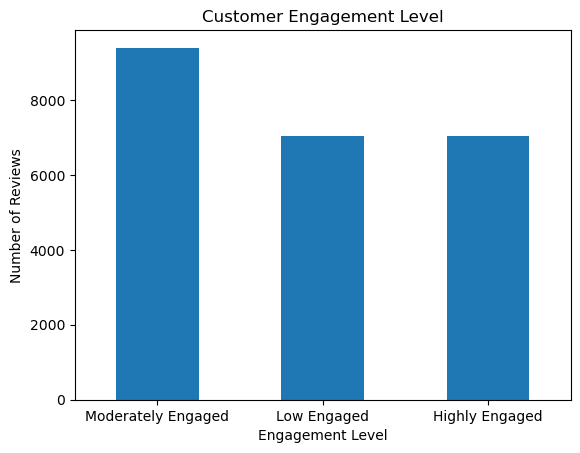

In [25]:
data['engagement_level'].value_counts().plot(
    kind='bar',
    title='Customer Engagement Level'
)

plt.xlabel('Engagement Level')
plt.ylabel('Number of Reviews')
plt.xticks(rotation=0)
plt.show()

In [26]:
print("Engagement thresholds:")
print("Low:", round(low_limit, 2))
print("High:", round(high_limit, 2))

print("\nEngagement summary:")
print(data['engagement_level'].value_counts())

print("\nAverage engagement score:")
print(round(data['engagement_score'].mean(), 2))

Engagement thresholds:
Low: 37.02
High: 58.66

Engagement summary:
engagement_level
Moderately Engaged    9395
Low Engaged           7049
Highly Engaged        7042
Name: count, dtype: int64

Average engagement score:
46.37


In [27]:
data.to_csv(
    'womens_clothing_engagement.csv',
    index=False
)

print("Dataset saved successfully!")

Dataset saved successfully!
